# Power and Minimal Detectable Effect Notebook

This notebook examines how sample size, baseline outcome rates, and treatment allocation affect the sensitivity of an assignment-based experiment. It extends the [ITT inference analysis](02_itt_inference.ipynb) with reverse minimum detectable effect (MDE) calculations, sample-size requirements for specified relative lifts, and allocation scenarios at a fixed total sample size.

Visits remain the primary outcome and conversions the secondary outcome. All calculations use a two-sided significance level of **5%** and target power of **80%**, with independent binomial outcomes and a normal approximation. These calculations assess the experiment’s ability to detect specified effects, using the released benchmark’s control rates as baseline inputs.

In [149]:
from pathlib import Path
import os
import sys

root = Path(r"D:\Projects\A_B_Test\Project")
os.chdir(root)

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.run_sql import run_sql
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import scipy
import statsmodels
from scipy.stats import norm
from scipy.optimize import brentq
import seaborn as sns
from matplotlib.ticker import PercentFormatter, MaxNLocator

print('Project Setup')
print("-" * 72)
print(f"{'Working directory':<32}: {Path.cwd()}")

Project Setup
------------------------------------------------------------------------
Working directory               : D:\Projects\A_B_Test\Project


## Descriptive Statistics

The SQL step generates arm-level metrics and joint assignment/exposure/outcome counts. This section reads `arm_summary.csv`, whose denominators include every observation in each assigned arm.

| Measure | Control (`treatment = 0`) | Treatment (`treatment = 1`) |
| --- | ---: | ---: |
| Observations | 2,096,937 | 11,882,655 |
| Visits | 80,105 | 576,824 |
| Visit rate | 3.820096% | 4.854336% |
| Conversions | 4,063 | 36,711 |
| Conversion rate | 0.193759% | 0.308946% |

The two arms contain **13,979,592 observations** in total, with approximately 85% assigned to treatment. Both observed outcome rates are higher in treatment.

In [150]:
run_sql("sql/02_experiment_metrics.sql")
arm_summary = pd.read_csv("results/arm_summary.csv")
print('Descriptive Statistics')
print("-" * 72)
print("Assigned-arm counts")
print(
    arm_summary.loc[:, ["treatment", "n", "n_visit", "n_conversion", "n_exposure"]]
    .assign(treatment=lambda table: table["treatment"].map({0: "Control (0)", 1: "Treatment (1)"}))
    .rename(columns={
        "treatment": "Group", "n": "Users", "n_visit": "Visits",
        "n_conversion": "Conversions", "n_exposure": "Exposed",
    }).to_string(
        index=False,
        formatters={
            "Users": "{:,.0f}".format, "Visits": "{:,.0f}".format,
            "Conversions": "{:,.0f}".format, "Exposed": "{:,.0f}".format,
        },
    )
)
print("\nAssigned-arm rates")
print(
    arm_summary.loc[:, ["treatment", "visit_rate", "conversion_rate", "exposure_rate"]]
    .assign(treatment=lambda table: table["treatment"].map({0: "Control (0)", 1: "Treatment (1)"}))
    .rename(columns={
        "treatment": "Group", "visit_rate": "Visit rate",
        "conversion_rate": "Conversion rate", "exposure_rate": "Exposure rate",
    }).to_string(
        index=False,
        formatters={
            "Visit rate": "{:.6%}".format, "Conversion rate": "{:.6%}".format,
            "Exposure rate": "{:.6%}".format,
        },
    )
)

Count
9
Completed: 02_experiment_metrics.sql
Descriptive Statistics
------------------------------------------------------------------------
Assigned-arm counts
        Group      Users  Visits Conversions Exposed
  Control (0)  2,096,937  80,105       4,063       0
Treatment (1) 11,882,655 576,824      36,711 428,212

Assigned-arm rates
        Group Visit rate Conversion rate Exposure rate
  Control (0)  3.820096%       0.193759%     0.000000%
Treatment (1)  4.854336%       0.308946%     3.603673%


## Statistical Power Framework

The framework concerns a two-sided comparison of two independent proportions. It relates four design quantities: the false-positive rate, desired power at a specified alternative, the effect size, and the allocation-adjusted sample size.

Two complementary calculations follow. **Reverse MDE** fixes the available arm sizes and solves for a detectable difference. **Sample-size planning** fixes the target difference and solves for the required arm sizes. Allocation scenarios then hold the total sample fixed while changing its division between treatment and control.

- **Significance level ($\alpha$):** The nominal probability of rejecting an equal-rates null hypothesis when it is true; here $\alpha=0.05$ for each outcome.
- **Power ($1-\beta$):** The probability of rejecting that null at a specified true alternative; the target is $0.80$.
- **Minimum detectable effect ($\delta$):** The positive difference in outcome probabilities corresponding to the target power under the planning approximation.
- **Baseline rate ($p_C$):** The control outcome probability used for planning; here it is estimated from the released sample.
- **Allocation ratio ($r$):** Treatment sample size divided by control sample size, $r=n_T/n_C$.

For a positive target difference, set $p_T=p_C+\delta$ and define the allocation-weighted pooled rate as $\bar p=(p_C+r p_T)/(1+r)$. The implemented approximation gives the required **control-arm** size:

$$
n_C \approx
\frac{
\left[
 z_{1-\alpha/2}\sqrt{\bar p(1-\bar p)(1+1/r)}
 +z_{1-\beta}\sqrt{p_C(1-p_C)+p_T(1-p_T)/r}
\right]^2
}{\delta^2}.
$$

The treatment and total requirements are $n_T=r n_C$ and $N=(1+r)n_C$. The first variance term corresponds to the pooled null approximation; the second uses the outcome probabilities under the specified alternative.

All reported MDEs are positive-lift scenarios, and the target power is approximate. An absolute effect in probability units is multiplied by 100 to obtain **percentage points (pp)**; a relative lift is $\delta/p_C$.

## Reverse MDE

Fix the observed arm sizes and baseline rate, then solve for the positive difference $\delta$ that makes the required control sample equal to the available control sample. This describes the sensitivity implied by the current sample and allocation at the selected significance and power levels.

The calculation varies the hypothetical treatment rate through $p_T=p_C+\delta$. 

The following cell extracts the observed arm sizes, event counts, and rates for both outcomes. The reverse calculations use **2,096,937 control observations**, **11,882,655 treatment observations**, and the corresponding control baseline. Both outcomes share the same allocation ratio.

In [151]:
p_c_visit = arm_summary.loc[arm_summary['treatment'] == 0, 'visit_rate'].iloc[0]
p_t_visit = arm_summary.loc[arm_summary['treatment'] == 1, 'visit_rate'].iloc[0]
visit_c = arm_summary.loc[arm_summary['treatment'] == 0, 'n_visit'].iloc[0]
visit_t = arm_summary.loc[arm_summary['treatment'] == 1, 'n_visit'].iloc[0]
n_c = arm_summary.loc[arm_summary['treatment'] == 0, 'n'].iloc[0]
n_t = arm_summary.loc[arm_summary['treatment'] == 1, 'n'].iloc[0]

r = n_t / n_c

con_c = arm_summary.loc[arm_summary['treatment'] == 0, 'n_conversion'].iloc[0]
con_t = arm_summary.loc[arm_summary['treatment'] == 1, 'n_conversion'].iloc[0]
p_c_con = arm_summary.loc[arm_summary['treatment'] == 0, 'conversion_rate'].iloc[0]
p_t_con = arm_summary.loc[arm_summary['treatment'] == 1, 'conversion_rate'].iloc[0]


`required_n_control` evaluates the sample-size approximation for a candidate effect $\delta$ and allocation ratio $r$. Its result is an unrounded control-arm requirement; the associated treatment requirement is $r$ times that value.

This helper is used both to find the MDE for the available sample and to estimate sample sizes for chosen relative lifts. Feasible positive alternatives must satisfy $0<\delta<1-p_C$.

In [152]:
def required_n_control(
    p_c, delta, r,
    alpha=0.05, power=0.80
):
    p_t = p_c + delta

    z_alpha = norm.ppf(1 - alpha / 2)
    z_beta = norm.ppf(power)

    p_bar = (p_c + r * p_t) / (1 + r)

    term_null = z_alpha * np.sqrt(
        p_bar * (1 - p_bar) * (1 + 1/r)
    )

    term_alt = z_beta * np.sqrt(
        p_c * (1 - p_c)
        + p_t * (1 - p_t) / r
    )

    return ((term_null + term_alt) / delta) ** 2

`reverse_mde` applies Brent's bracketed root-finding method to the sample-size gap:

$$
g(\delta)=n_{C,\mathrm{required}}(p_C,\delta,r)-n_{C,\mathrm{available}}.
$$

The numerical solution satisfies $g(\delta)=0$ within the search tolerance. The code searches between a small positive effect and a treatment probability just below one.

| Outcome | Reverse MDE (percentage points) | Relative MDE (%) |
| --- | ---: | ---: |
| Visit | 0.040354 | 1.056356% |
| Conversion | 0.009369 | 4.835479% |

In [153]:
def reverse_mde(
    p_c, n_c, n_t,
    alpha=0.05, power=0.80
):
    r = n_t / n_c

    def sample_size_gap(delta):
        
        n_required = required_n_control(
                        p_c, delta, r, alpha, power
                    ) 
        n_actual = n_c
        return n_required - n_actual

    return brentq(
        sample_size_gap,
        1e-12,
        1 - p_c - 1e-8
    )

mde_visit = reverse_mde(
    p_c_visit, n_c, n_t
)

mde_conversion = reverse_mde(
    p_c_con, n_c, n_t
)

print("Reverse MDE")
print("-" * 72)
print(f"{'Visit MDE (pp)':<32}: {mde_visit * 100:.6f}")
print(f"{'Conversion MDE (pp)':<32}: {mde_conversion * 100:.6f}")

relative_mde_visit = mde_visit / p_c_visit
relative_mde_conversion = mde_conversion / p_c_con

print(f"{'Visit relative MDE (%)':<32}: {relative_mde_visit:.6%}")
print(f"{'Conversion relative MDE (%)':<32}: {relative_mde_conversion:.6%}")

Reverse MDE
------------------------------------------------------------------------
Visit MDE (pp)                  : 0.040354
Conversion MDE (pp)             : 0.009369
Visit relative MDE (%)          : 1.056356%
Conversion relative MDE (%)     : 4.835479%


A local approximation checks the scale of the numerical solutions. If the detectable change is small enough that $p_T\approx p_C$, both variance terms can be evaluated near the control baseline:

$$
\delta\approx(z_{1-\alpha/2}+z_{1-\beta})
\sqrt{p_C(1-p_C)\left(\frac{1}{n_C}+\frac{1}{n_T}\right)}.
$$

The saved approximate MDEs are **0.040224 pp for visits** and **0.009228 pp for conversions**, compared with **0.040354 pp** and **0.009369 pp** from root finding.

In [154]:
def reverse_mde_simple(p_C, p_T, alpha =0.05, power = 0.80):
    
    z_alpha = norm.ppf(1 - alpha / 2)
    z_beta = norm.ppf(power)

    mde = (z_alpha + z_beta) * np.sqrt(
        p_C * (1 - p_C) * (1 / n_c + 1 / n_t)
    )

    return mde

print("Approximate Reverse MDE")
print("-" * 72)
print(f"{'Visit MDE (pp)':<32}: {reverse_mde_simple(p_c_visit, p_t_visit) * 100:.6f}")
print(f"{'Conversion MDE (pp)':<32}: {reverse_mde_simple(p_c_con, p_t_con) * 100:.6f}")

Approximate Reverse MDE
------------------------------------------------------------------------
Visit MDE (pp)                  : 0.040224
Conversion MDE (pp)             : 0.009228


## Sample Size Scenarios

Fix a target relative lift $L$ and convert it to an absolute probability difference, $\delta=p_C L$. The following cells evaluate **2%, 5%, and 10% relative improvements** for each outcome, keeping the observed treatment-to-control ratio, two-sided $\alpha=0.05$, and 80% target power unchanged.

| Outcome | Target relative lift | Absolute target (pp) | Required total observations |
| --- | ---: | ---: | ---: |
| Visit | 2% | 0.076402 | 3,922,324 |
| Visit | 5% | 0.191005 | 638,939 |
| Visit | 10% | 0.382010 | 164,444 |
| Conversion | 2% | 0.003875 | 80,286,055 |
| Conversion | 5% | 0.009688 | 13,088,026 |
| Conversion | 10% | 0.019376 | 3,372,635 |

Smaller target effects require larger samples. At an equal relative target, conversions require substantially more observations.

In [155]:
relative_lift = [0.02, 0.05, 0.10]
n_c_visit_need_list = []

for lift in relative_lift:
    delta = p_c_visit * lift

    n_c_need = required_n_control(
        p_c=p_c_visit,
        delta=delta,
        r= n_t / n_c
    )

    n_t_need = n_c_need * r

    n_c_visit_need_list.append({
        "relative_lift": lift,
        "absolute_mde_pp": delta * 100,
        "n_control": np.ceil(n_c_need),
        "n_treatment": np.ceil(n_t_need),
        "n_total": np.ceil(n_c_need + n_t_need)
    })

sample_scenarios_visit = pd.DataFrame(n_c_visit_need_list)
print("Sample Size Scenarios | Visit")
print("-" * 72)
print(
    sample_scenarios_visit.rename(columns={
        "relative_lift": "Relative lift",
        "absolute_mde_pp": "Absolute MDE (pp)",
        "n_control": "Control users",
        "n_treatment": "Treatment users",
        "n_total": "Total users",
    }).to_string(
        index=False,
        formatters={
            "Relative lift": "{:.0%}".format,
            "Absolute MDE (pp)": "{:.6f}".format,
            "Control users": "{:,.0f}".format,
            "Treatment users": "{:,.0f}".format,
            "Total users": "{:,.0f}".format,
        },
    )
)

Sample Size Scenarios | Visit
------------------------------------------------------------------------
Relative lift Absolute MDE (pp) Control users Treatment users Total users
           2%          0.076402       588,349       3,333,976   3,922,324
           5%          0.191005        95,841         543,099     638,939
          10%          0.382010        24,667         139,778     164,444


In [156]:
relative_lift = [0.02, 0.05, 0.10]
n_c_con_need_list = []

for lift in relative_lift:
    delta = p_c_con * lift

    n_c_need = required_n_control(
        p_c=p_c_con,
        delta=delta,
        r= n_t / n_c
    )

    n_t_need = n_c_need * r

    n_c_con_need_list.append({
        "relative_lift": lift,
        "absolute_mde_pp": delta * 100,
        "n_control": np.ceil(n_c_need),
        "n_treatment": np.ceil(n_t_need),
        "n_total": np.ceil(n_c_need + n_t_need)
    })

sample_scenarios_con = pd.DataFrame(n_c_con_need_list)
print("Sample Size Scenarios | Conversion")
print("-" * 72)
print(
    sample_scenarios_con.rename(columns={
        "relative_lift": "Relative lift",
        "absolute_mde_pp": "Absolute MDE (pp)",
        "n_control": "Control users",
        "n_treatment": "Treatment users",
        "n_total": "Total users",
    }).to_string(
        index=False,
        formatters={
            "Relative lift": "{:.0%}".format,
            "Absolute MDE (pp)": "{:.6f}".format,
            "Control users": "{:,.0f}".format,
            "Treatment users": "{:,.0f}".format,
            "Total users": "{:,.0f}".format,
        },
    )
)

Sample Size Scenarios | Conversion
------------------------------------------------------------------------
Relative lift Absolute MDE (pp) Control users Treatment users Total users
           2%          0.003875    12,042,898      68,243,157  80,286,055
           5%          0.009688     1,963,203      11,124,824  13,088,026
          10%          0.019376       505,895       2,866,740   3,372,635


### Power Curve

The following figures show **required sample size versus target relative lift at a fixed 80% power**. Each plot includes separate control, treatment, and total requirements at the three evaluated targets. The connecting lines guide comparisons between those scenarios; intermediate targets were not separately evaluated.

Both plots hold the baseline and observed allocation ratio fixed. Their different vertical scales reflect the much larger sample needed to detect the same relative improvement in conversions.

For **visits**, required total sample size decreases from approximately **3.92 million** at a 2% relative lift to **638,939** at 5% and **164,444** at 10%.

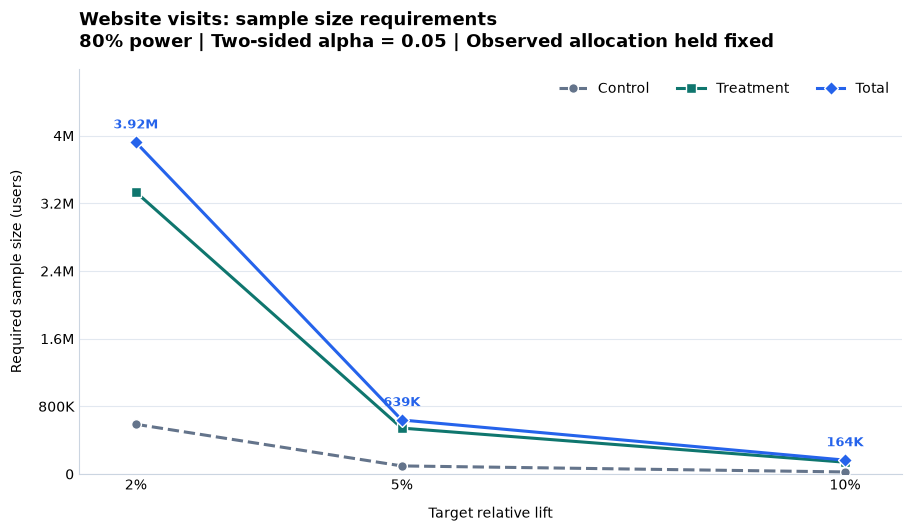

In [157]:
from matplotlib.ticker import PercentFormatter, FuncFormatter, MaxNLocator

fig, ax = plt.subplots(figsize=(9, 5.2), layout="constrained")
for column, label, color, marker, style in [
    ("n_control", "Control", "#64748B", "o", "--"),
    ("n_treatment", "Treatment", "#0F766E", "s", "-"),
    ("n_total", "Total", "#2563EB", "D", "-"),
]:
    ax.plot(sample_scenarios_visit["relative_lift"], sample_scenarios_visit[column],
            color=color, marker=marker, linestyle=style, linewidth=2.2,
            markersize=7, markeredgecolor="white", label=label, zorder=3)

for lift, total in zip(sample_scenarios_visit["relative_lift"], sample_scenarios_visit["n_total"]):
    text = f"{total / 1_000_000:.2f}M" if total >= 1_000_000 else f"{total / 1_000:.0f}K"
    ax.annotate(text, (lift, total), xytext=(0, 10),
                textcoords="offset points", ha="center", fontsize=9,
                color="#2563EB", fontweight="bold")

ax.set_title("Website visits: sample size requirements\n"
             "80% power | Two-sided alpha = 0.05 | Observed allocation held fixed",
             loc="left", fontsize=13, fontweight="bold", pad=16)
ax.set_xlabel("Target relative lift", labelpad=10)
ax.set_ylabel("Required sample size (users)", labelpad=10)
ax.set_xticks(sample_scenarios_visit["relative_lift"])
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.yaxis.set_major_formatter(FuncFormatter(
    lambda value, _: f"{value / 1_000_000:g}M" if value >= 1_000_000
    else (f"{value / 1_000:g}K" if value > 0 else "0")))
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.set_ylim(0, sample_scenarios_visit["n_total"].max() * 1.22)
ax.margins(x=0.08)
ax.grid(axis="y", color="#E2E8F0", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#CBD5E1")
ax.tick_params(axis="both", length=0, labelsize=10)
ax.legend(frameon=False, loc="upper right", ncol=3)
plt.show()


For **conversions**, the corresponding totals are approximately **80.29 million**, **13.09 million**, and **3.37 million**. A 2% relative conversion improvement is only about **0.003875 percentage points**. Read the vertical-axis values directly when comparing the two figures, since their scales differ.

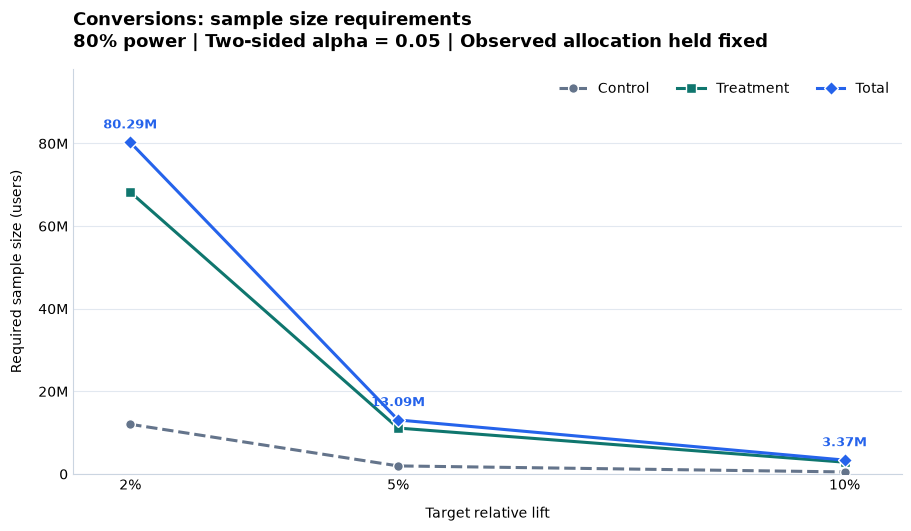

In [158]:
from matplotlib.ticker import PercentFormatter, FuncFormatter, MaxNLocator

fig, ax = plt.subplots(figsize=(9, 5.2), layout="constrained")
for column, label, color, marker, style in [
    ("n_control", "Control", "#64748B", "o", "--"),
    ("n_treatment", "Treatment", "#0F766E", "s", "-"),
    ("n_total", "Total", "#2563EB", "D", "-"),
]:
    ax.plot(sample_scenarios_con["relative_lift"], sample_scenarios_con[column],
            color=color, marker=marker, linestyle=style, linewidth=2.2,
            markersize=7, markeredgecolor="white", label=label, zorder=3)

for lift, total in zip(sample_scenarios_con["relative_lift"], sample_scenarios_con["n_total"]):
    text = f"{total / 1_000_000:.2f}M" if total >= 1_000_000 else f"{total / 1_000:.0f}K"
    ax.annotate(text, (lift, total), xytext=(0, 10),
                textcoords="offset points", ha="center", fontsize=9,
                color="#2563EB", fontweight="bold")

ax.set_title("Conversions: sample size requirements\n"
             "80% power | Two-sided alpha = 0.05 | Observed allocation held fixed",
             loc="left", fontsize=13, fontweight="bold", pad=16)
ax.set_xlabel("Target relative lift", labelpad=10)
ax.set_ylabel("Required sample size (users)", labelpad=10)
ax.set_xticks(sample_scenarios_con["relative_lift"])
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.yaxis.set_major_formatter(FuncFormatter(
    lambda value, _: f"{value / 1_000_000:g}M" if value >= 1_000_000
    else (f"{value / 1_000:g}K" if value > 0 else "0")))
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.set_ylim(0, sample_scenarios_con["n_total"].max() * 1.22)
ax.margins(x=0.08)
ax.grid(axis="y", color="#E2E8F0", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#CBD5E1")
ax.tick_params(axis="both", length=0, labelsize=10)
ax.legend(frameon=False, loc="upper right", ncol=3)
plt.show()


## Allocation Scenarios

Hold total sample size fixed at **13,979,592**, retain each outcome's control baseline, and vary only the division of observations between arms. In this code, `allocation` means the **control share** $q$:

$$
n_C=Nq,\qquad n_T=N(1-q),\qquad r=\frac{1-q}{q}.
$$

The evaluated control shares range from **5% to 95% in 5-percentage-point steps**.

| Outcome | MDE at observed allocation (pp) | Lowest tested MDE (pp) | Control share at lowest tested MDE |
| --- | ---: | ---: | ---: |
| Visit | 0.040354 | 0.028777 | 50% |
| Conversion | 0.009369 | 0.006646 | 50% |

Among the evaluated allocations, **50% control / 50% treatment** produces the smallest MDE for both outcomes.

In [159]:
allocations = np.arange(0.05, 1, 0.05)
N = arm_summary["n"].sum()

mde_visit_list = []
mde_con_list = []

for allocation in allocations:
    n_c_scenario = N * allocation
    n_t_scenario = N * (1 - allocation)

    mde_visit = reverse_mde(
        p_c_visit, n_c_scenario, n_t_scenario
    )

    mde_conversion = reverse_mde(
        p_c_con, n_c_scenario, n_t_scenario
    )

    mde_visit_list.append(mde_visit)
    mde_con_list.append(mde_conversion)

print("Allocation Scenarios")
print("-" * 72)
print(
    pd.DataFrame({
        "Control share": allocations,
        "Visit MDE (pp)": np.array(mde_visit_list) * 100,
        "Conversion MDE (pp)": np.array(mde_con_list) * 100,
    }).to_string(
        index=False,
        formatters={
            "Control share": "{:.0%}".format,
            "Visit MDE (pp)": "{:.6f}".format,
            "Conversion MDE (pp)": "{:.6f}".format,
        },
    )
)


Allocation Scenarios
------------------------------------------------------------------------
Control share Visit MDE (pp) Conversion MDE (pp)
           5%       0.066272            0.015522
          10%       0.048066            0.011190
          15%       0.040354            0.009369
          20%       0.036007            0.008347
          25%       0.033252            0.007700
          30%       0.031414            0.007268
          35%       0.030176            0.006978
          40%       0.029376            0.006789
          45%       0.028925            0.006682
          50%       0.028777            0.006646
          55%       0.028920            0.006678
          60%       0.029367            0.006780
          65%       0.030163            0.006963
          70%       0.031394            0.007247
          75%       0.033225            0.007670
          80%       0.035968            0.008304
          85%       0.040297            0.009307
          90%       0.04

### Graphs

Each panel plots MDE in **percentage points** against the **control allocation share**. The highlighted bar marks the smallest MDE among the tested allocations; both panels identify 50% control. The higher bars at more unequal allocations show the sensitivity cost of allocating too few observations to one arm while holding the total fixed.

The visit and conversion panels have separate vertical scales.

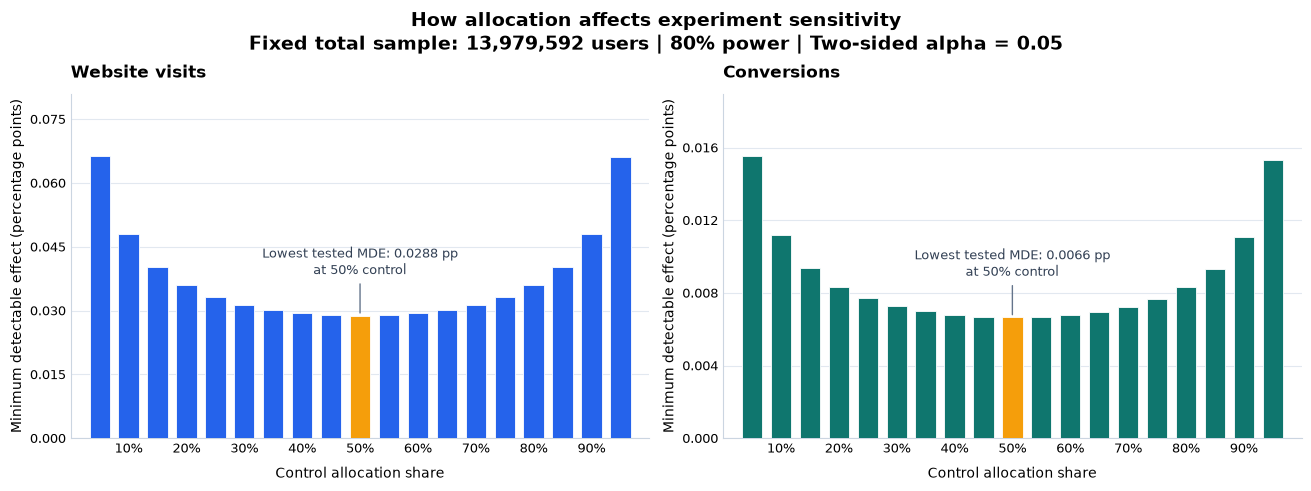

In [160]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), layout="constrained")

for ax, values, title, color in [
    (axes[0], mde_visit_list, "Website visits", "#2563EB"),
    (axes[1], mde_con_list, "Conversions", "#0F766E"),
]:
    mde_pp = np.asarray(values) * 100
    best_index = int(np.argmin(mde_pp))
    colors = [color] * len(allocations)
    colors[best_index] = "#F59E0B"

    ax.bar(allocations, mde_pp, width=0.035, color=colors,
           edgecolor="white", linewidth=0.6, zorder=3)
    ax.annotate(
        f"Lowest tested MDE: {mde_pp[best_index]:.4f} pp\n"
        f"at {allocations[best_index]:.0%} control",
        xy=(allocations[best_index], mde_pp[best_index]),
        xytext=(0, 30), textcoords="offset points", ha="center",
        fontsize=9, color="#334155",
        arrowprops={"arrowstyle": "-", "color": "#64748B"},
    )
    ax.set_title(title, loc="left", fontsize=12, fontweight="bold", pad=12)
    ax.set_xlabel("Control allocation share", labelpad=8)
    ax.set_ylabel("Minimum detectable effect (percentage points)")
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    ax.set_xticks(np.arange(0.1, 1.0, 0.1))
    ax.set_xlim(0, 1)
    ax.set_ylim(0, mde_pp.max() * 1.22)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.grid(axis="y", color="#E2E8F0", linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#CBD5E1")
    ax.tick_params(axis="both", length=0, labelsize=9)

fig.suptitle(
    "How allocation affects experiment sensitivity\n"
    f"Fixed total sample: {N:,.0f} users | 80% power | Two-sided alpha = 0.05",
    fontsize=14, fontweight="bold",
)
plt.show()


## Design Implications  

- **Current sensitivity:** The observed sample and allocation imply MDEs of **0.040354 pp for visits** and **0.009369 pp for conversions**, corresponding to relative MDEs of **1.056356%** and **4.835479%**, respectively, at 80% target power.
- **Planning trade-off:** A 2% relative lift requires about **3.92 million observations for visits** versus **80.29 million for conversions**. The primary visit outcome is substantially easier to study at that relative target.
- **Allocation choice:** At the same total sample, a 50%/50% split gives the lowest tested MDEs.